# Projetos-teste PERT/CPM — Simulação Monte Carlo

Notebook organizado para rodar com **Run All** (de cima para baixo).
A classe é importada de `classe_pert_universal.py`; depois de alterar o arquivo, reinicie o kernel.

### Nota sobre a distribuição Normal

A Normal foi incluída no comparativo como **baseline ingênuo** (contraponto didático), não como recomendação de modelagem para atividades reais: sendo simétrica, ela ignora a assimetria típica de durações de projeto (em geral há mais risco de atraso do que de adiantamento — motivo pelo qual o PERT clássico adotou a Beta). Ela usa μ = M (moda) e σ = (P − O)/6 (ver `classe_pert_universal.py`), e serve para evidenciar, nas métricas de comparação (KS, Wasserstein, KL/Jensen-Shannon) e nos percentis altos (P90/P95), o quanto ignorar essa assimetria distorce a estimativa de risco em relação às distribuições assimétricas (Beta, Triangular, Lognormal, Weibull).

In [15]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classe_pert_universal import PERTUniversalEngine

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

N_SIMULACOES = 50000
SEED = 42

## Projeto 1 — Rede com correlação e condição

- Correlação entre B e G: −0,3
- Condição em F: se o início mais cedo de F (ES) for ≤ 23 dias, F ~ (6, 9, 12); senão, F ~ (6, 12, 18)

In [16]:
engine1 = PERTUniversalEngine(nome_projeto="Projeto 1 - Condicional")

engine1.adicionar_atividade("A", O=4, M=5, P=7, descricao="Atividade A")
engine1.adicionar_atividade("B", O=1, M=7, P=13, predecessoras=["A"], descricao="Atividade B")
engine1.adicionar_atividade("D", O=5, M=8, P=11, descricao="Atividade D")
engine1.adicionar_atividade("E", O=6, M=7, P=8, predecessoras=["D"], descricao="Atividade E")
engine1.adicionar_atividade("C", O=9, M=11, P=14, predecessoras=["B", "D"], descricao="Atividade C")
engine1.adicionar_atividade("G", O=6, M=15, P=24, predecessoras=["C"], descricao="Atividade G")
engine1.adicionar_atividade("F", O=6, M=9, P=12, predecessoras=["C", "E"], descricao="Atividade F")

# Correlação entre B e G
atividades = list(engine1.atividades)
df_corr = pd.DataFrame(np.eye(len(atividades)), index=atividades, columns=atividades)
df_corr.loc["B", "G"] = df_corr.loc["G", "B"] = -0.3
engine1.definir_matriz_correlacao(df_corr)

# Condição de F definida por dados
engine1.adicionar_condicao(
    "F", limite_es=23, cenario_ate=(6, 9, 12), cenario_acima=(6, 12, 18)
)

In [17]:
print("PREMISSAS PERT DO PROJETO 1")
display(engine1.gerar_tabela_premissas().sort_values(by="Atividade"))

PREMISSAS PERT DO PROJETO 1


,Atividade,Predecessoras,Otimista (O),Mais Provável (M),Pessimista (P),Média (TE),Variância (σ²),Desvio Padrão (σ),Desvio Beta-PERT
0,A,-,4,5,7,5.17,0.25,0.50,0.55
1,B,A,1,7,13,7.00,4.00,2.00,2.27
4,C,"B, D",9,11,14,11.17,0.69,0.83,0.94
2,D,-,5,8,11,8.00,1.00,1.00,1.13
3,E,D,6,7,8,7.00,0.11,0.33,0.38
6,F (ES <= 23),"C, E",6,9,12,9.00,1.00,1.00,1.13
7,F (ES > 23),"C, E",6,12,18,12.00,4.00,2.00,2.27
5,G,C,6,15,24,15.00,9.00,3.00,3.40


In [18]:
comparacao1 = engine1.comparar_com_pert_tradicional(n_simulacoes=N_SIMULACOES, seed=SEED)
df_resumo1 = comparacao1["resumo"]
print("RESUMO COMPARATIVO: DISTRIBUIÇÕES SIMULADAS x PERT TRADICIONAL")
display(df_resumo1)
print("Caminho crítico do PERT tradicional:", " -> ".join(engine1.resultado_pert_tradicional["caminho_critico"]))
print("DURACOES DAS SIMULACOES:")
display(comparacao1["duracoes"])
print("CAMINHOS DAS SIMULACOES:")
display(comparacao1["caminhos"])

for dist in engine1.DISTRIBUICOES:
    print()
    print(f"CRITICIDADE DOS CAMINHOS - {dist}")
    display(engine1.analisar_criticidade_caminhos(dist))

RESUMO COMPARATIVO: DISTRIBUIÇÕES SIMULADAS x PERT TRADICIONAL


,Métrica / Percentil,Beta,Triangular,Lognormal,Weibull,PERT_Tradicional
0,Média do Projeto,38.77,39.23,39.88,39.58,38.33
1,Desvio Padrão,3.51,3.74,2.48,3.74,3.73
2,Percentil 10 (P10),34.08,34.24,36.85,34.72,33.55
3,Percentil 25 (P25),36.47,36.79,38.17,37.12,35.81
4,Percentil 50 (P50),38.90,39.33,39.72,39.57,38.33
5,Percentil 75 (P75),41.18,41.78,41.42,42.06,40.85
6,Percentil 80 (P80),41.74,42.39,41.86,42.68,41.48
7,Percentil 85 (P85),42.37,43.08,42.39,43.42,42.20
8,Percentil 90 (P90),43.16,43.93,43.12,44.35,43.12
9,Percentil 95 (P95),44.39,45.24,44.21,45.75,44.48


Caminho crítico do PERT tradicional: A -> B -> C -> G
DURACOES DAS SIMULACOES:


,Distribuição,Média simulada (dias),DP simulado (dias),Média PERT tradicional (dias),DP PERT tradicional (dias),R quantis,KS (D),KS (p-valor),Wasserstein-1 (dias),KL(sim || PERT) (nats),KL(PERT || sim) (nats),Jensen-Shannon (nats)
0,Beta,38.77,3.51,38.33,3.73,1.00,0.07,0.00,0.47,0.02,0.02,0.00
1,Triangular,39.23,3.74,38.33,3.73,1.00,0.11,0.00,0.89,0.03,0.03,0.01
2,Lognormal,39.88,2.48,38.33,3.73,1.00,0.25,0.00,1.60,0.23,0.52,0.07
3,Weibull,39.58,3.74,38.33,3.73,1.00,0.14,0.00,1.24,0.06,0.06,0.01


CAMINHOS DAS SIMULACOES:


,Distribuição,Caminho,Criticidade Monte Carlo (%),PERT tradicional (%),Diferença absoluta (p.p.),Distância TV dos caminhos (%),Líder coincide com PERT
0,Beta,A -> B -> C -> F,17.12,0.00,17.12,22.63,True
1,Beta,A -> B -> C -> G,77.37,100.00,22.63,22.63,True
2,Beta,D -> C -> F,0.08,0.00,0.08,22.63,True
3,Beta,D -> C -> G,5.43,0.00,5.43,22.63,True
4,Beta,D -> E -> F,0.00,0.00,0.00,22.63,True
5,Triangular,A -> B -> C -> F,19.45,0.00,19.45,25.88,True
6,Triangular,A -> B -> C -> G,74.12,100.00,25.88,25.88,True
7,Triangular,D -> C -> F,0.18,0.00,0.18,25.88,True
8,Triangular,D -> C -> G,6.25,0.00,6.25,25.88,True
9,Triangular,D -> E -> F,0.00,0.00,0.00,25.88,True


... (4 outputs left out)


CRITICIDADE DOS CAMINHOS - Lognormal


,Caminho,Média (Dias),P90 (Dias),Criticidade (%)
0,Caminho 1 (A -> B -> C -> G),39.77,43.05,91.17
1,Caminho 2 (A -> B -> C -> F),35.54,39.52,8.62
3,Caminho 4 (D -> C -> G),35.30,38.60,0.21
2,Caminho 3 (D -> E -> F),26.86,29.66,0.00
4,Caminho 5 (D -> C -> F),31.07,34.16,0.00



CRITICIDADE DOS CAMINHOS - Weibull


,Caminho,Média (Dias),P90 (Dias),Criticidade (%)
0,Caminho 1 (A -> B -> C -> G),39.10,44.10,76.88
1,Caminho 2 (A -> B -> C -> F),34.73,40.61,17.91
3,Caminho 4 (D -> C -> G),34.74,39.92,5.09
4,Caminho 5 (D -> C -> F),30.37,34.69,0.12
2,Caminho 3 (D -> E -> F),26.15,30.06,0.00


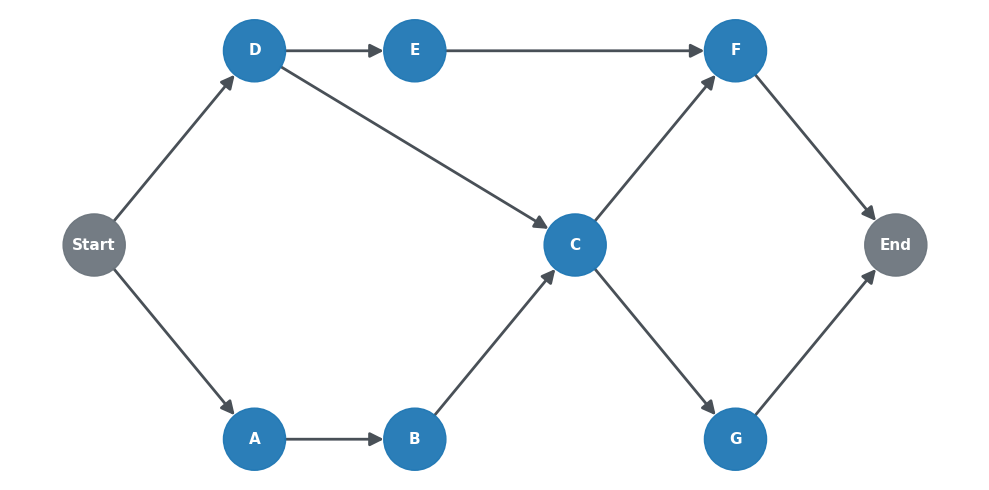

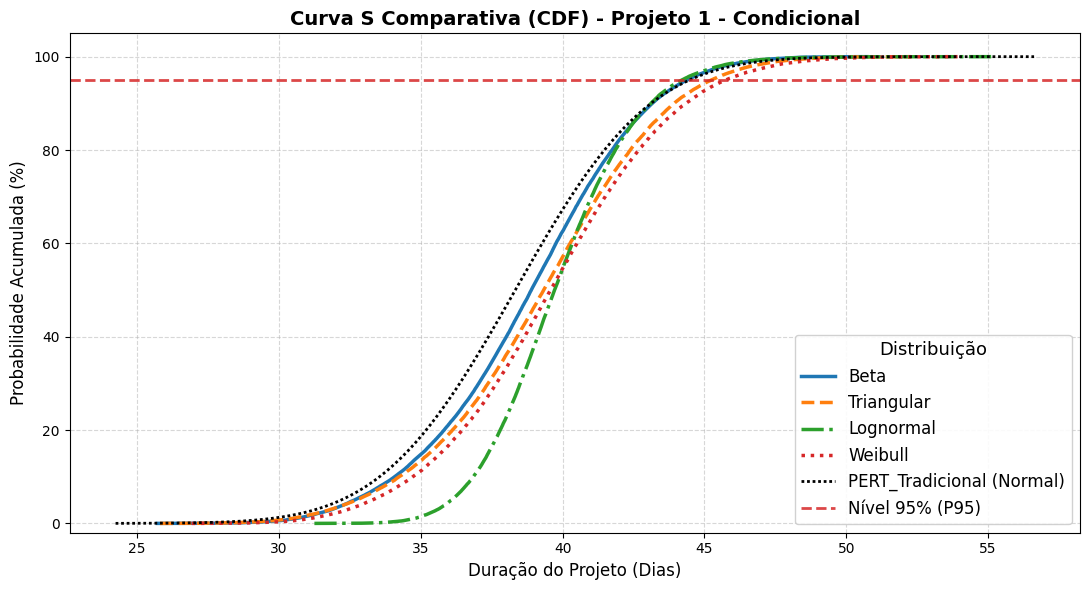

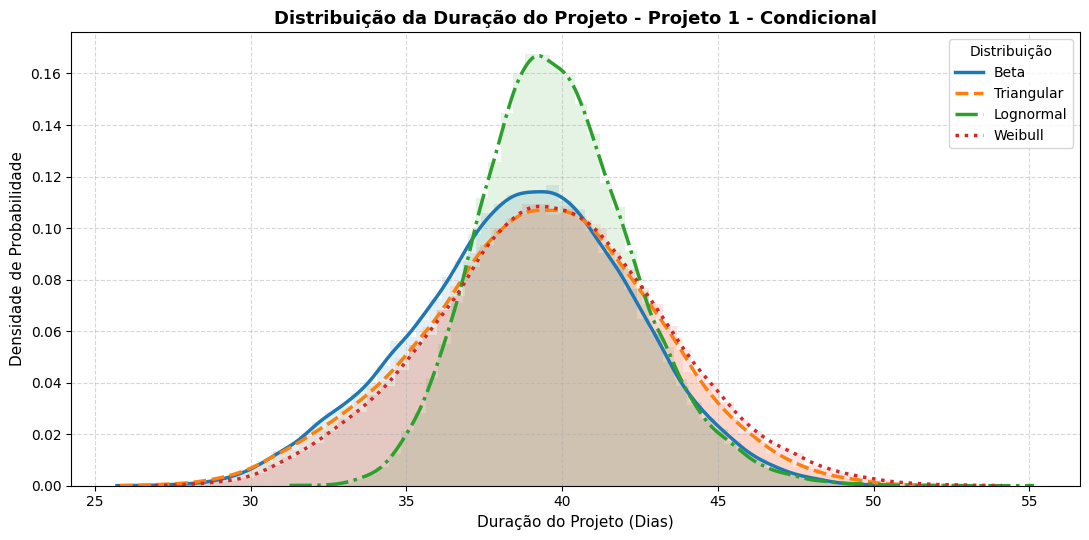

In [19]:
engine1.plotar_grafo()
engine1.plotar_curva_s_comparativa()
_ = engine1.plotar_histograma_comparativo()

### Resultados para o artigo — Projeto 1

Exportação de tabelas/figuras, testes pareados (KS + Holm-Bonferroni), robustez entre seeds e convergência de Monte Carlo.

In [ ]:
resultado_export1 = engine1.exportar_resultados(
    diretorio="resultados_artigo", n_simulacoes=N_SIMULACOES, seed=SEED
)
print("TESTES PAREADOS (KS + Holm-Bonferroni) - PROJETO 1")
display(resultado_export1["testes_ks"])

In [ ]:
print("ROBUSTEZ ENTRE SEEDS (30 réplicas) - PROJETO 1")
df_robustez1 = engine1.analisar_robustez()
display(df_robustez1)

In [ ]:
print("CONVERGÊNCIA DE MONTE CARLO (distribuição Beta) - PROJETO 1")
df_convergencia1 = engine1.analisar_convergencia(distrib="Beta")
display(df_convergencia1)
_ = engine1.plotar_convergencia(df_convergencia1, "Beta")

## Projeto 2 — Exemplo 12 (Aldo Mattos)

A atividade D tem duração fixa (O = M = P = 3) e é tratada como constante nas quatro distribuições.

In [20]:
engine2 = PERTUniversalEngine(nome_projeto="Projeto Exemplo Aldo Mattos")

engine2.adicionar_atividade("A", O=2, M=6, P=10, descricao="Serviços Preliminares")
engine2.adicionar_atividade("B", O=1, M=3, P=4, predecessoras=["A"], descricao="Escavação")
engine2.adicionar_atividade("C", O=4, M=8, P=9, predecessoras=["B"], descricao="Fundação")
engine2.adicionar_atividade("D", O=3, M=3, P=3, descricao="Mobilização")
engine2.adicionar_atividade("E", O=5, M=6, P=8, predecessoras=["D"], descricao="Montagem")
engine2.adicionar_atividade("F", O=3, M=7, P=11, predecessoras=["C", "E"], descricao="Estrutura")
engine2.adicionar_atividade("G", O=6, M=11, P=14, descricao="Instalações Externas")
engine2.adicionar_atividade("H", O=3, M=4, P=9, predecessoras=["F", "G"], descricao="Acabamento")

print("PREMISSAS PERT DO PROJETO 2")
display(engine2.gerar_tabela_premissas())

PREMISSAS PERT DO PROJETO 2


,Atividade,Predecessoras,Otimista (O),Mais Provável (M),Pessimista (P),Média (TE),Variância (σ²),Desvio Padrão (σ),Desvio Beta-PERT
0,A,-,2,6,10,6.00,1.78,1.33,1.51
1,B,A,1,3,4,2.83,0.25,0.50,0.55
2,C,B,4,8,9,7.50,0.69,0.83,0.87
3,D,-,3,3,3,3.00,0.00,0.00,0.00
4,E,D,5,6,8,6.17,0.25,0.50,0.55
5,F,"C, E",3,7,11,7.00,1.78,1.33,1.51
6,G,-,6,11,14,10.67,1.78,1.33,1.49
7,H,"F, G",3,4,9,4.67,1.00,1.00,1.02


In [21]:
comparacao2 = engine2.comparar_com_pert_tradicional(n_simulacoes=N_SIMULACOES, seed=SEED)
df_resumo2 = comparacao2["resumo"]
print("RESUMO COMPARATIVO: DISTRIBUIÇÕES SIMULADAS x PERT TRADICIONAL")
display(df_resumo2)
print("Caminho crítico do PERT tradicional:", " -> ".join(engine2.resultado_pert_tradicional["caminho_critico"]))
print("DURACOES DAS SIMULACOES:")
display(comparacao2["duracoes"])
print("CAMINHOS DAS SIMULACOES:")
display(comparacao2["caminhos"])

for dist in engine2.DISTRIBUICOES:
    print()
    print(f"CRITICIDADE DOS CAMINHOS - {dist}")
    display(engine2.analisar_criticidade_caminhos(dist))

RESUMO COMPARATIVO: DISTRIBUIÇÕES SIMULADAS x PERT TRADICIONAL


,Métrica / Percentil,Beta,Triangular,Lognormal,Weibull,PERT_Tradicional
0,Média do Projeto,28.00,28.00,29.45,29.00,28.00
1,Desvio Padrão,2.59,2.92,1.85,2.72,2.35
2,Percentil 10 (P10),24.67,24.23,27.26,25.59,24.99
3,Percentil 25 (P25),26.22,26.00,28.17,27.12,26.42
4,Percentil 50 (P50),28.00,27.97,29.29,28.89,28.00
5,Percentil 75 (P75),29.78,30.00,30.55,30.77,29.58
6,Percentil 80 (P80),30.21,30.50,30.90,31.25,29.97
7,Percentil 85 (P85),30.71,31.07,31.31,31.82,30.43
8,Percentil 90 (P90),31.36,31.78,31.86,32.54,31.01
9,Percentil 95 (P95),32.28,32.85,32.71,33.62,31.86


Caminho crítico do PERT tradicional: A -> B -> C -> F -> H
DURACOES DAS SIMULACOES:


,Distribuição,Média simulada (dias),DP simulado (dias),Média PERT tradicional (dias),DP PERT tradicional (dias),R quantis,KS (D),KS (p-valor),Wasserstein-1 (dias),KL(sim || PERT) (nats),KL(PERT || sim) (nats),Jensen-Shannon (nats)
0,Beta,28.00,2.59,28.00,2.35,1.00,0.03,0.00,0.21,0.01,0.01,0.00
1,Triangular,28.00,2.92,28.00,2.35,1.00,0.06,0.00,0.48,0.06,0.05,0.01
2,Lognormal,29.45,1.85,28.00,2.35,0.99,0.28,0.00,1.45,0.27,0.61,0.08
3,Weibull,29.00,2.72,28.00,2.35,1.00,0.15,0.00,1.00,0.12,0.08,0.02


CAMINHOS DAS SIMULACOES:


,Distribuição,Caminho,Criticidade Monte Carlo (%),PERT tradicional (%),Diferença absoluta (p.p.),Distância TV dos caminhos (%),Líder coincide com PERT
0,Beta,A -> B -> C -> F -> H,100.00,100.00,0.00,0.00,True
1,Beta,D -> E -> F -> H,0.00,0.00,0.00,0.00,True
2,Beta,G -> H,0.00,0.00,0.00,0.00,True
3,Triangular,A -> B -> C -> F -> H,99.88,100.00,0.12,0.12,True
4,Triangular,D -> E -> F -> H,0.12,0.00,0.12,0.12,True
5,Triangular,G -> H,0.00,0.00,0.00,0.12,True
6,Lognormal,A -> B -> C -> F -> H,100.00,100.00,0.00,0.00,True
7,Lognormal,D -> E -> F -> H,0.00,0.00,0.00,0.00,True
8,Lognormal,G -> H,0.00,0.00,0.00,0.00,True
9,Weibull,A -> B -> C -> F -> H,100.00,100.00,0.00,0.00,True


... (4 outputs left out)


CRITICIDADE DOS CAMINHOS - Lognormal


,Caminho,Média (Dias),P90 (Dias),Criticidade (%)
0,Caminho 1 (A -> B -> C -> F -> H),29.45,31.86,100.00
1,Caminho 2 (D -> E -> F -> H),21.25,23.26,0.00
2,Caminho 3 (G -> H),15.89,17.62,0.00



CRITICIDADE DOS CAMINHOS - Weibull


,Caminho,Média (Dias),P90 (Dias),Criticidade (%)
0,Caminho 1 (A -> B -> C -> F -> H),29.00,32.54,100.00
1,Caminho 2 (D -> E -> F -> H),21.33,24.19,0.00
2,Caminho 3 (G -> H),15.82,18.33,0.00


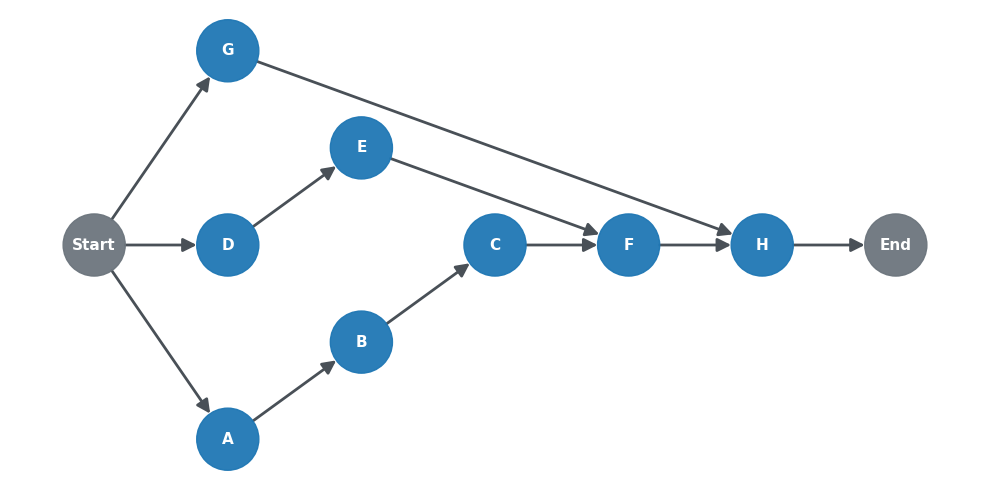

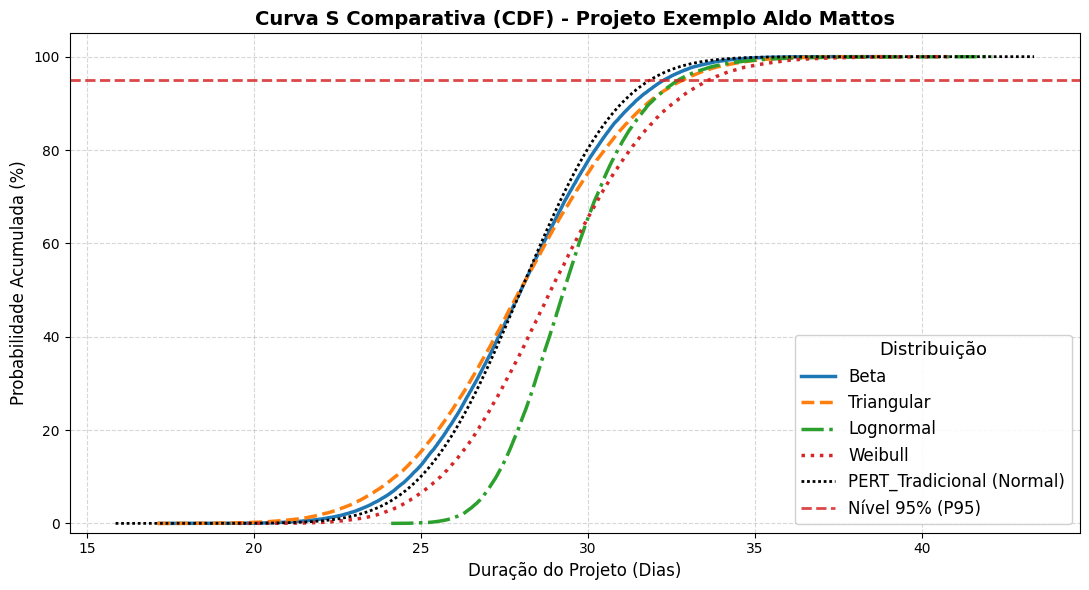

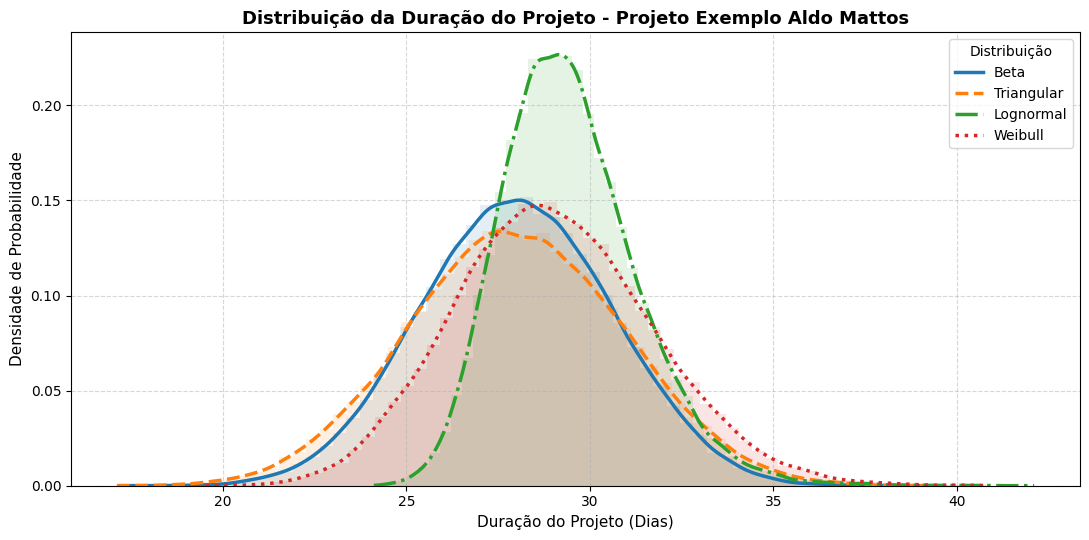

In [22]:
engine2.plotar_grafo()
engine2.plotar_curva_s_comparativa()
_ = engine2.plotar_histograma_comparativo()

### Resultados para o artigo — Projeto 2

Exportação de tabelas/figuras, testes pareados (KS + Holm-Bonferroni), robustez entre seeds e convergência de Monte Carlo.

In [ ]:
resultado_export2 = engine2.exportar_resultados(
    diretorio="resultados_artigo", n_simulacoes=N_SIMULACOES, seed=SEED
)
print("TESTES PAREADOS (KS + Holm-Bonferroni) - PROJETO 2")
display(resultado_export2["testes_ks"])

In [ ]:
print("ROBUSTEZ ENTRE SEEDS (30 réplicas) - PROJETO 2")
df_robustez2 = engine2.analisar_robustez()
display(df_robustez2)

In [ ]:
print("CONVERGÊNCIA DE MONTE CARLO (distribuição Beta) - PROJETO 2")
df_convergencia2 = engine2.analisar_convergencia(distrib="Beta")
display(df_convergencia2)
_ = engine2.plotar_convergencia(df_convergencia2, "Beta")

## Projetos sintéticos — sensibilidade à assimetria

Redes geradas por `PERTUniversalEngine.gerar_sintetico`, variando o parâmetro de assimetria
O-M-P (0 = quase simétrico; 0,9 = fortemente assimétrico à direita, como durações reais de
atividades). O objetivo é generalizar as conclusões além dos 2 projetos-exemplo manuais:
mostrar sistematicamente como a divergência entre as distribuições (sobretudo da Normal, o
baseline ingênuo simétrico) cresce com a assimetria.

In [ ]:
GRID_ASSIMETRIA = [0.0, 0.3, 0.6, 0.9]
N_ATIVIDADES_SINTETICO = 8
SEED_SINTETICO = 7

resultados_sinteticos = {}

for assimetria in GRID_ASSIMETRIA:
    eng = PERTUniversalEngine.gerar_sintetico(
        n_atividades=N_ATIVIDADES_SINTETICO, assimetria=assimetria, seed=SEED_SINTETICO
    )
    prefixo_sintetico = f"sintetico_assimetria_{assimetria:g}".replace(".", "_")
    comparacao = eng.comparar_com_pert_tradicional(n_simulacoes=N_SIMULACOES, seed=SEED)
    df_ks = eng.testes_pareados_ks(n_simulacoes=N_SIMULACOES, seed=SEED)
    eng.exportar_resultados(
        diretorio="resultados_artigo/sinteticos",
        prefixo=prefixo_sintetico,
        n_simulacoes=N_SIMULACOES,
        seed=SEED,
    )
    # Salva também em projetos_teste/, no formato lido pela interface (ui = abrir_interface()),
    # para que o sintético apareça no dropdown "Salvos" junto com Projeto 1 e Projeto 2.
    eng.exportar_para_interface(nome_arquivo=prefixo_sintetico)
    resultados_sinteticos[assimetria] = {
        "engine": eng, "comparacao": comparacao, "ks": df_ks
    }
    print(f"Assimetria={assimetria:g} -> OK ({eng.nome_projeto})")

In [ ]:
# Tendência: estatística KS (D) da Normal contra cada distribuição assimétrica,
# em função do grau de assimetria da rede sintética.
linhas_tendencia = []
for assimetria, dados in resultados_sinteticos.items():
    linha = {"Assimetria": assimetria}
    for _, r in dados["ks"].iterrows():
        par = {r["Distribuição 1"], r["Distribuição 2"]}
        if "Normal" in par:
            outra = (par - {"Normal"}).pop()
            linha[f"KS(D) Normal vs {outra}"] = r["KS (D)"]
    linhas_tendencia.append(linha)

df_tendencia_assimetria = pd.DataFrame(linhas_tendencia).sort_values("Assimetria")
print("TENDÊNCIA: DIVERGÊNCIA (KS) DA NORMAL x ASSIMETRIA")
display(df_tendencia_assimetria)

plt.figure(figsize=(8, 5))
for coluna in df_tendencia_assimetria.columns:
    if coluna == "Assimetria":
        continue
    plt.plot(
        df_tendencia_assimetria["Assimetria"],
        df_tendencia_assimetria[coluna],
        marker="o",
        linewidth=2.0,
        label=coluna,
    )
plt.xlabel("Assimetria da rede sintética (0 = simétrico, 0,9 = fortemente assimétrico)")
plt.ylabel("Estatística KS (D) vs. Normal")
plt.title("Divergência da Normal (baseline ingênuo) conforme a assimetria cresce")
plt.legend(title="Comparação", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
eng_sintetico_rep = resultados_sinteticos[0.9]["engine"]

print(f"ROBUSTEZ ENTRE SEEDS (30 réplicas) - {eng_sintetico_rep.nome_projeto}")
df_robustez_sintetico = eng_sintetico_rep.analisar_robustez()
display(df_robustez_sintetico)

print(f"CONVERGÊNCIA DE MONTE CARLO (distribuição Beta) - {eng_sintetico_rep.nome_projeto}")
df_convergencia_sintetico = eng_sintetico_rep.analisar_convergencia(distrib="Beta")
display(df_convergencia_sintetico)
_ = eng_sintetico_rep.plotar_convergencia(df_convergencia_sintetico, "Beta")

## Carregando um projeto salvo em CSV

Os projetos salvos pela interface ficam em `projetos_teste/` (três arquivos por projeto:
`_atividades.csv`, `_correlacoes.csv`, `_condicoes.csv`).

PREMISSAS PERT DO PROJETO (CSV)


,Atividade,Predecessoras,Otimista (O),Mais Provável (M),Pessimista (P),Média (TE),Variância (σ²),Desvio Padrão (σ),Desvio Beta-PERT
0,A,-,2.00,6.00,10.00,6.00,1.78,1.33,1.51
1,B,A,1.00,3.00,4.00,2.83,0.25,0.50,0.55
2,C,B,4.00,8.00,9.00,7.50,0.69,0.83,0.87
3,D,-,3.00,3.00,3.00,3.00,0.00,0.00,0.00
4,E,D,5.00,6.00,8.00,6.17,0.25,0.50,0.55
5,F,"C, E",3.00,7.00,11.00,7.00,1.78,1.33,1.51
6,G,-,6.00,11.00,14.00,10.67,1.78,1.33,1.49
7,H,"F, G",3.00,4.00,9.00,4.67,1.00,1.00,1.02


RESUMO COMPARATIVO: DISTRIBUI??ES SIMULADAS x PERT TRADICIONAL


,Métrica / Percentil,Beta,Triangular,Lognormal,Weibull,PERT_Tradicional
0,Média do Projeto,28.00,28.00,29.45,29.00,28.00
1,Desvio Padrão,2.59,2.92,1.85,2.72,2.35
2,Percentil 10 (P10),24.67,24.23,27.26,25.59,24.99
3,Percentil 25 (P25),26.22,26.00,28.17,27.12,26.42
4,Percentil 50 (P50),28.00,27.97,29.29,28.89,28.00
5,Percentil 75 (P75),29.78,30.00,30.55,30.77,29.58
6,Percentil 80 (P80),30.21,30.50,30.90,31.25,29.97
7,Percentil 85 (P85),30.71,31.07,31.31,31.82,30.43
8,Percentil 90 (P90),31.36,31.78,31.86,32.54,31.01
9,Percentil 95 (P95),32.28,32.85,32.71,33.62,31.86


Caminho cr?tico do PERT tradicional: A -> B -> C -> F -> H
DURACOES DAS SIMULACOES:


,Distribuição,Média simulada (dias),DP simulado (dias),Média PERT tradicional (dias),DP PERT tradicional (dias),R quantis,KS (D),KS (p-valor),Wasserstein-1 (dias),KL(sim || PERT) (nats),KL(PERT || sim) (nats),Jensen-Shannon (nats)
0,Beta,28.00,2.59,28.00,2.35,1.00,0.03,0.00,0.21,0.01,0.01,0.00
1,Triangular,28.00,2.92,28.00,2.35,1.00,0.06,0.00,0.48,0.06,0.05,0.01
2,Lognormal,29.45,1.85,28.00,2.35,0.99,0.28,0.00,1.45,0.27,0.61,0.08
3,Weibull,29.00,2.72,28.00,2.35,1.00,0.15,0.00,1.00,0.12,0.08,0.02


... (6 outputs left out)


CRITICIDADE DOS CAMINHOS - Lognormal


,Caminho,Média (Dias),P90 (Dias),Criticidade (%)
0,Caminho 1 (A -> B -> C -> F -> H),29.45,31.86,100.00
1,Caminho 2 (D -> E -> F -> H),21.25,23.26,0.00
2,Caminho 3 (G -> H),15.89,17.62,0.00



CRITICIDADE DOS CAMINHOS - Weibull


,Caminho,Média (Dias),P90 (Dias),Criticidade (%)
0,Caminho 1 (A -> B -> C -> F -> H),29.00,32.54,100.00
1,Caminho 2 (D -> E -> F -> H),21.33,24.19,0.00
2,Caminho 3 (G -> H),15.82,18.33,0.00


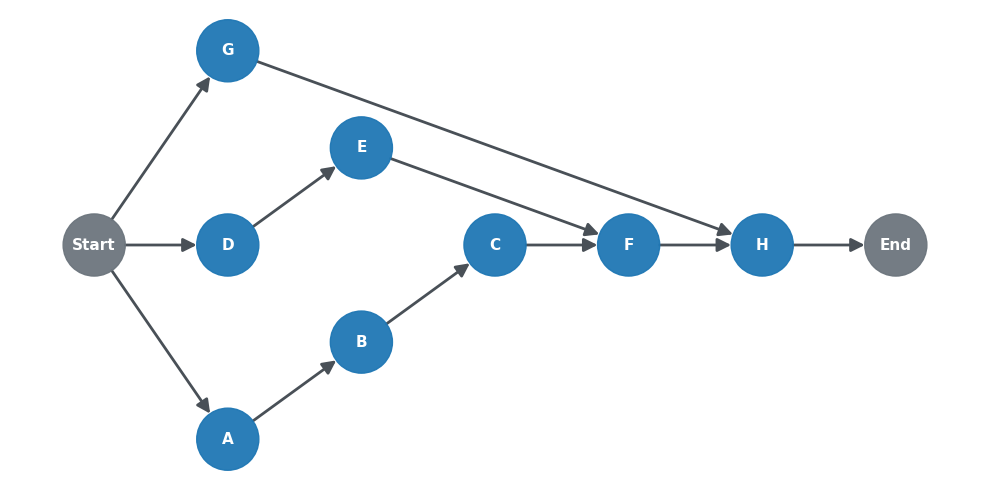

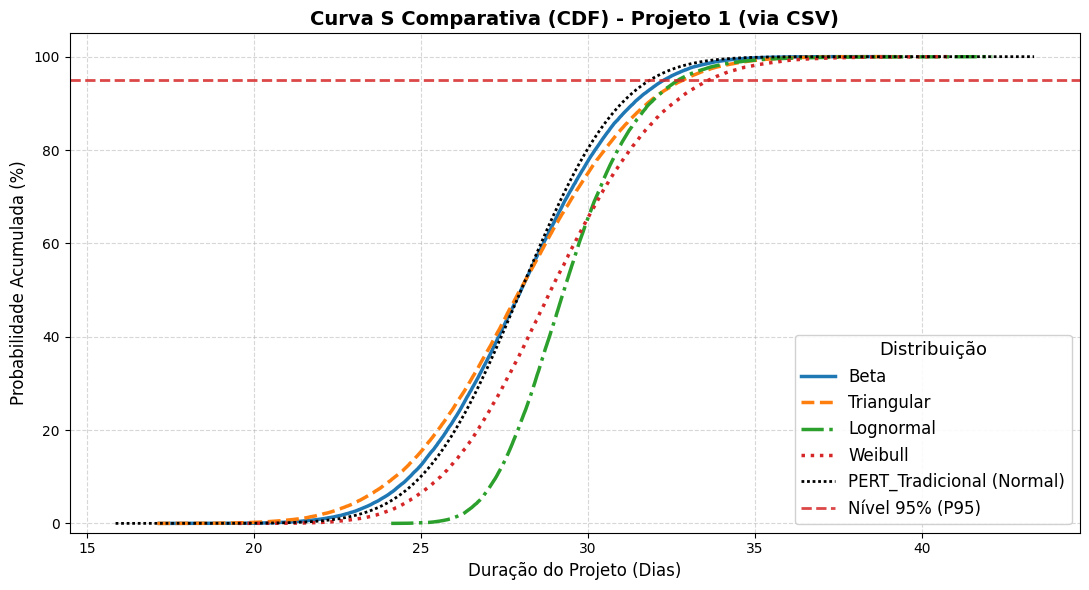

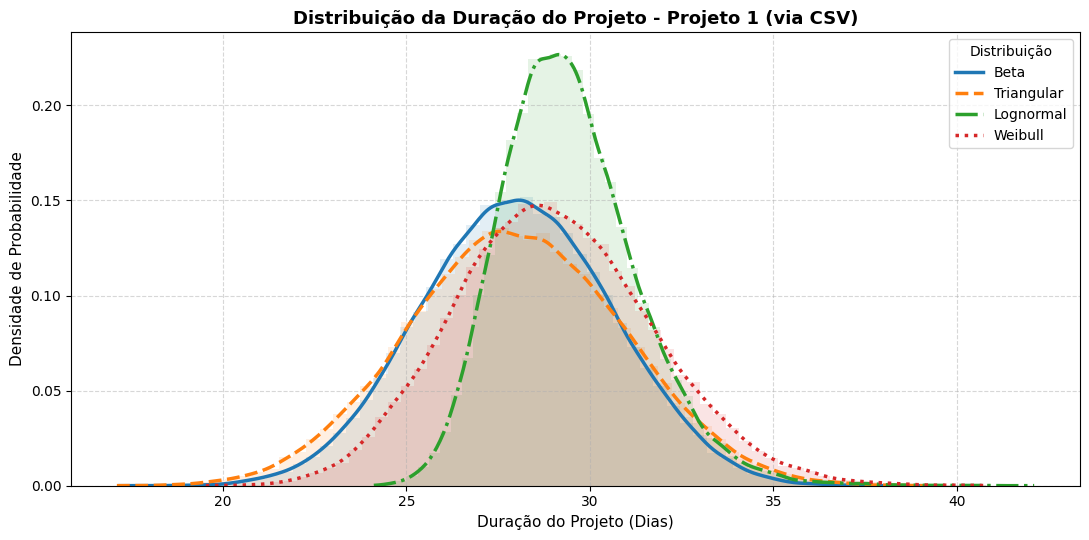

In [23]:
#base = "projetos_teste/projeto1_condicional"
base="projetos_teste/projeto2_aldo_mattos"

engine_csv = PERTUniversalEngine(nome_projeto="Projeto 1 (via CSV)")
engine_csv.carregar_dados(
    f"{base}_atividades.csv",
    f"{base}_correlacoes.csv",
    f"{base}_condicoes.csv",
)

print("PREMISSAS PERT DO PROJETO (CSV)")
display(engine_csv.gerar_tabela_premissas().sort_values(by="Atividade"))

comparacao_csv = engine_csv.comparar_com_pert_tradicional(n_simulacoes=N_SIMULACOES, seed=SEED)
df_resumo_csv = comparacao_csv["resumo"]
print("RESUMO COMPARATIVO: DISTRIBUI??ES SIMULADAS x PERT TRADICIONAL")
display(df_resumo_csv)
print("Caminho cr?tico do PERT tradicional:", " -> ".join(engine_csv.resultado_pert_tradicional["caminho_critico"]))
print("DURACOES DAS SIMULACOES:")
display(comparacao_csv["duracoes"])
print("CAMINHOS DAS SIMULACOES:")
display(comparacao_csv["caminhos"])

for dist in engine_csv.DISTRIBUICOES:
    print()
    print(f"CRITICIDADE DOS CAMINHOS - {dist}")
    display(engine_csv.analisar_criticidade_caminhos(dist))

engine_csv.plotar_grafo()
engine_csv.plotar_curva_s_comparativa()
_ = engine_csv.plotar_histograma_comparativo()

## Interface de entrada (widgets)

Cadastre atividades, correlações e condições nas abas, salve o projeto e clique em **Simular**.
Depois da simulação, a engine fica disponível em `ui.engine`.

In [14]:
from interface_pert import abrir_interface

ui = abrir_interface()